# Risk Prediction Overview

## Phase 0: Directory location and Modules linked

In [48]:
import sys
from pathlib import Path

# Add the project root to Python path
project_root = Path.cwd().parent  # Goes up one level from notebooks/
sys.path.insert(0, str(project_root))

In [49]:
# 1. Enable Auto-reloading
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt

# 2. Import your heavy logic from your Python file
from core.gnn_layer.risk_predict import (
    fetch_graph_from_neo4j, 
    RiskEscalationGNN, 
    train_model,
    graph_edge_oversample, 
    evaluate_with_kfold
)

from core.kg_sna_layer.graph_builder import(
    AsyncKnowledgeGraphManager,
    wipe_sna_metrics
)

print("Environment linked and modules loaded successfully!")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Environment linked and modules loaded successfully!


## Phase 1: Fetching data

In [62]:
from core.config import graph_base
kg_manager = AsyncKnowledgeGraphManager(graph_base.URL, graph_base.USER, graph_base.PASS)
print("Fetching graph data from Neo4j... Done.")

Fetching graph data from Neo4j... Done.


In case of SNA metrics already loaded, it can be cleaned to show the process from the beggining.

In [63]:
wipe_sna_metrics(graph_base.URL, graph_base.USER, graph_base.PASS)
baseline_data, enriched_data, reverse_mapping = fetch_graph_from_neo4j(graph_base.URL, graph_base.USER, graph_base.PASS)

print(f"Successfully loaded {baseline_data.num_nodes} nodes and {baseline_data.num_edges} edges before SNA calculations.")
print(f"Total High-Risk Edges (Class 1): {int(enriched_data.y.sum().item())}")

✅ Deleted SNA_TIE_STRENGTH edges.
✅ Removed structural metrics (betweenness, eigenvector, etc.) from nodes.
🧹 Graph successfully reset to its pure semantic state!
Successfully loaded 52 nodes and 184 edges before SNA calculations.
Total High-Risk Edges (Class 1): 19


Now, the SNA metrics can be added to the neo4j database.

In [64]:
#Running calculate_sna_metrics()
await kg_manager.calculate_sna_metrics()
baseline_data_sna, enriched_data_sna, reverse_mapping_sna = fetch_graph_from_neo4j(graph_base.URL, graph_base.USER, graph_base.PASS)

print(f"Successfully loaded {baseline_data_sna.num_nodes} nodes and {baseline_data_sna.num_edges} edges with SNA calculations.")
print(f"Total High-Risk Edges (Class 1): {int(enriched_data_sna.y.sum().item())}")

✅ Structural Metrics (Betweenness, Eigenvector, Closeness) updated.
Successfully loaded 52 nodes and 184 edges with SNA calculations.
Total High-Risk Edges (Class 1): 19


## Phase 2: Data distribution

Load all imports related to this phase

C:\Users\dhara\AppData\Local\Temp\ipykernel_22992\519620922.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


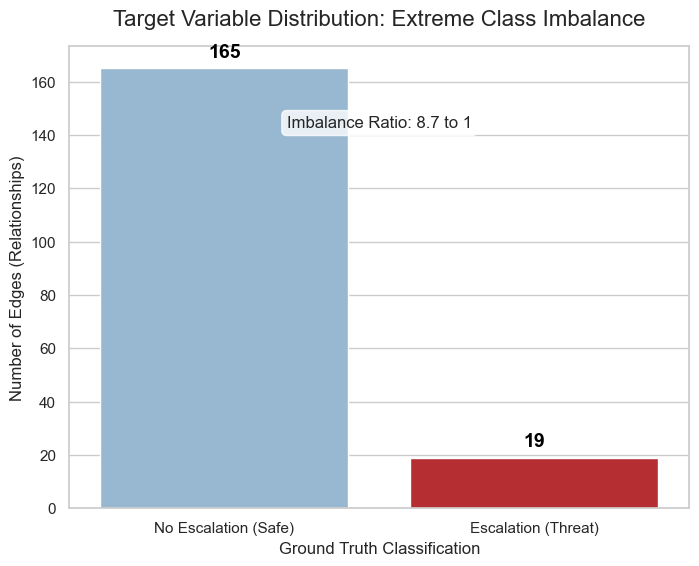

In [65]:
import seaborn as sns
import numpy as np
from datetime import datetime
y_true = enriched_data_sna.y.cpu().numpy()

unique, counts = np.unique(y_true, return_counts=True)
class_counts = dict(zip(unique, counts))

safe_count = class_counts.get(0, 0)
threat_count = class_counts.get(1, 0)

plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    x=['No Escalation (Safe)', 'Escalation (Threat)'], 
    y=[safe_count, threat_count], 
    palette=['#8ebad9', '#cb181d'] 
)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', 
                fontsize=14, fontweight='bold', color='black', 
                xytext=(0, 5), textcoords='offset points')

plt.title('Target Variable Distribution: Extreme Class Imbalance', fontsize=16, pad=15)
plt.ylabel('Number of Edges (Relationships)', fontsize=12)
plt.xlabel('Ground Truth Classification', fontsize=12)

imbalance_ratio = safe_count / threat_count if threat_count > 0 else 0
textstr = f'Imbalance Ratio: {imbalance_ratio:.1f} to 1'
plt.text(0.5, 0.85, textstr, transform=ax.transAxes, fontsize=12,
         verticalalignment='top', horizontalalignment='center',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))


timestamp_dist = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"class_distribution_{timestamp_dist}.png", dpi=300, bbox_inches='tight')

plt.show()

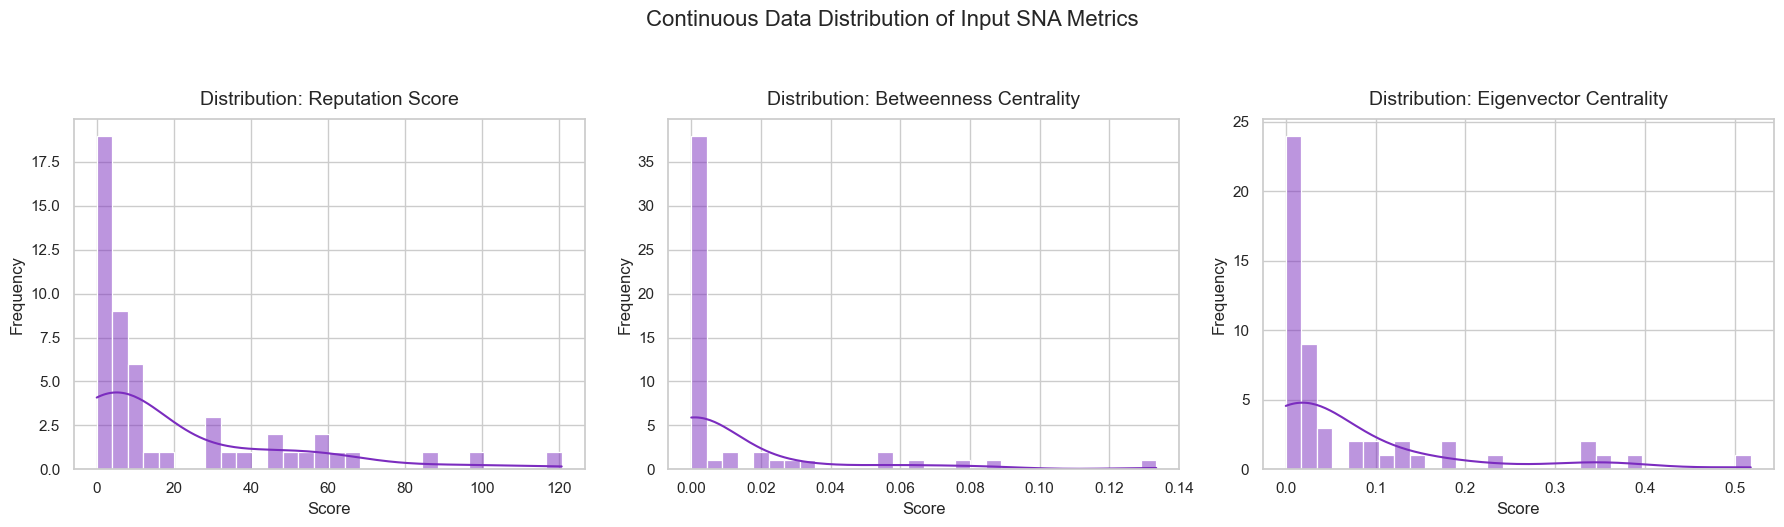

In [66]:
# 1. Extract the raw node features from your PyTorch object
# (We move it to CPU and convert to a numpy array)
node_features = enriched_data_sna.x.cpu().numpy()

# 2. Determine how many features you have
num_features = node_features.shape[1]

# 3. Set up a grid of plots side-by-side
fig, axes = plt.subplots(1, num_features, figsize=(6 * num_features, 5))

# Handle the case where there is only one feature (axes isn't an array)
if num_features == 1:
    axes = [axes]

# 4. Loop through each feature and plot its smooth distribution
# Create a list of the actual metric names
feature_names = ['Reputation Score', 'Betweenness Centrality', 'Eigenvector Centrality']

for i in range(num_features):
    sns.histplot(node_features[:, i], kde=True, ax=axes[i], color='#7b2cbf', bins=30)
    
    # Use the real names from the list!
    actual_name = feature_names[i] if i < len(feature_names) else f'Feature {i}'
    
    axes[i].set_title(f'Distribution: {actual_name}', fontsize=14, pad=10)
    axes[i].set_ylabel('Frequency')
    axes[i].set_xlabel('Score')

plt.suptitle('Continuous Data Distribution of Input SNA Metrics', fontsize=16, y=1.05)
plt.tight_layout()

# Save for your thesis
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"feature_distributions_{timestamp}.png", dpi=300, bbox_inches='tight')

plt.show()

## Phase 3: Initialize and train models

In [67]:
from sklearn.preprocessing import StandardScaler
import torch

# Initialize
baseline_model = RiskEscalationGNN(num_node_features=1, hidden_channels=16)
enriched_model = RiskEscalationGNN(num_node_features=3, hidden_channels=16)

# 1. Initialize the Scaler
scaler = StandardScaler()

# 2. Scale the Enriched Data features (X)
# We convert to numpy for sklearn, scale it, and convert back to a PyTorch tensor
scaled_features = scaler.fit_transform(enriched_data_sna.x.numpy())
enriched_data_sna.x = torch.tensor(scaled_features, dtype=torch.float)

# We must train on the balanced data so the loss curve matches your K-Fold reality
balanced_baseline_sna = graph_edge_oversample(baseline_data_sna)
balanced_enriched_sna = graph_edge_oversample(enriched_data_sna)

# 3. Train ONLY the models you intend to plot
print("--- Training Baseline Model with SNA ---")
trained_baseline_sna, loss_history_base_sna = train_model(baseline_model, balanced_baseline_sna, epochs=250)

print("\n--- Training Enriched Model with SNA ---")
trained_enriched_sna, loss_history_enriched_sna = train_model(enriched_model, balanced_enriched_sna, epochs=250)


--- Training Baseline Model with SNA ---
Epoch 000 | Loss: 0.6974
Epoch 020 | Loss: 0.6858
Epoch 040 | Loss: 0.6784
Epoch 060 | Loss: 0.6803
Epoch 080 | Loss: 0.6984
Epoch 100 | Loss: 0.6827
Epoch 120 | Loss: 0.6746
Epoch 140 | Loss: 0.6880
Epoch 160 | Loss: 0.6989
Epoch 180 | Loss: 0.6993
Epoch 200 | Loss: 0.7121
Epoch 220 | Loss: 0.6865
Epoch 240 | Loss: 0.6928

--- Training Enriched Model with SNA ---
Epoch 000 | Loss: 0.7209
Epoch 020 | Loss: 0.6932
Epoch 040 | Loss: 0.6744
Epoch 060 | Loss: 0.6495
Epoch 080 | Loss: 0.6048
Epoch 100 | Loss: 0.7095
Epoch 120 | Loss: 0.6339
Epoch 140 | Loss: 0.6030
Epoch 160 | Loss: 0.6003
Epoch 180 | Loss: 0.5752
Epoch 200 | Loss: 0.6638
Epoch 220 | Loss: 0.5640
Epoch 240 | Loss: 0.5947


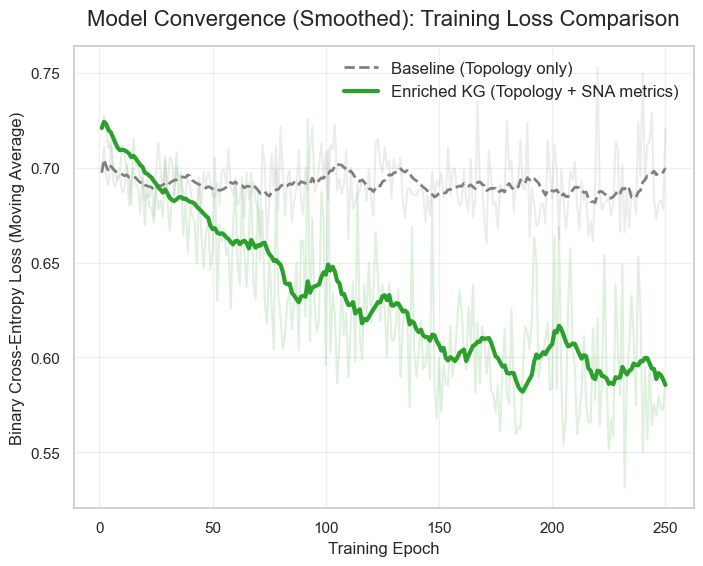

In [68]:
import pandas as pd

# 1. Apply a Rolling Average to smooth the noise (Standard Practice)
window_size = 15 # Averages the loss over 15 epochs

# Convert lists to Pandas Series to easily apply the rolling math
smooth_base = pd.Series(loss_history_base_sna).rolling(window=window_size, min_periods=1).mean()
smooth_enriched = pd.Series(loss_history_enriched_sna).rolling(window=window_size, min_periods=1).mean()

# 2. Set up the academic aesthetic
plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")
epochs_range = range(1, len(loss_history_enriched_sna) + 1)

# 3. Plot the SMOOTHED learning curves
plt.plot(epochs_range, smooth_base, color='gray', linestyle='--', linewidth=2, label='Baseline (Topology only)')
plt.plot(epochs_range, smooth_enriched, color='#2ca02c', linewidth=3, label='Enriched KG (Topology + SNA metrics)')

# Optional: Plot the raw, noisy data lightly in the background for total transparency
plt.plot(epochs_range, loss_history_enriched_sna, color='#2ca02c', alpha=0.15)
plt.plot(epochs_range, loss_history_base_sna, color='gray', alpha=0.15)

# 4. Add formatting and labels
plt.title('Model Convergence (Smoothed): Training Loss Comparison', fontsize=16, pad=15)
plt.xlabel('Training Epoch', fontsize=12)
plt.ylabel('Binary Cross-Entropy Loss (Moving Average)', fontsize=12)

plt.grid(True, alpha=0.3)
plt.legend(loc='upper right', fontsize=12)

# 5. Save and display
timestamp_conv = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"convergence_loss_smoothed_{timestamp_conv}.png", dpi=300, bbox_inches='tight')

plt.show()

## Phase 4: ROC & Precision-Recall

In [69]:
from sklearn.preprocessing import StandardScaler
import torch

def scale_node_features(data_obj):
    """
    Safely scales node features. Ignores the baseline [1.0] arrays, 
    but standardizes any SNA metrics (Reputation, Betweenness, etc.)
    so the neural network gradients don't explode.
    """
    # Only scale if the dataset has actual features (more than 1 column)
    if data_obj.x.shape[1] > 1:
        scaler = StandardScaler()
        scaled_x = scaler.fit_transform(data_obj.x.cpu().numpy())
        data_obj.x = torch.tensor(scaled_x, dtype=torch.float)
    return data_obj

# 1. Scale all the datasets to ensure the GNN can digest them
baseline_data = scale_node_features(baseline_data)
enriched_data = scale_node_features(enriched_data)
baseline_data_sna = scale_node_features(baseline_data_sna)
enriched_data_sna = scale_node_features(enriched_data_sna)

In [70]:
print("\n" + "="*40)
print("RUNNING K-FOLD ABLATION STUDY...")
print("="*40)

print("1/4: Evaluating Baseline Topology Only...")
y_true_b, preds_b = evaluate_with_kfold(baseline_model, baseline_data, epochs=250)

print("2/4: Evaluating Semantic Edges Only...")
y_true_e, preds_e = evaluate_with_kfold(enriched_model, enriched_data, epochs=250)

print("3/4: Evaluating Baseline + Global SNA...")
y_true_b_sna, preds_b_sna = evaluate_with_kfold(baseline_model, baseline_data_sna, epochs=250)

print("4/4: Evaluating Enriched KG + Global SNA...")
y_true_e_sna, preds_e_sna = evaluate_with_kfold(enriched_model, enriched_data_sna, epochs=250)
print("K-Fold Evaluation Complete!")


RUNNING K-FOLD ABLATION STUDY...
1/4: Evaluating Baseline Topology Only...
Epoch 000 | Loss: 0.6976
Epoch 020 | Loss: 0.7094
Epoch 040 | Loss: 0.6890
Epoch 060 | Loss: 0.6938
Epoch 080 | Loss: 0.7021
Epoch 100 | Loss: 0.6926
Epoch 120 | Loss: 0.6952
Epoch 140 | Loss: 0.6982
Epoch 160 | Loss: 0.6882
Epoch 180 | Loss: 0.6853
Epoch 200 | Loss: 0.7070
Epoch 220 | Loss: 0.6967
Epoch 240 | Loss: 0.6825
Epoch 000 | Loss: 0.6903
Epoch 020 | Loss: 0.6608
Epoch 040 | Loss: 0.6076
Epoch 060 | Loss: 0.6649
Epoch 080 | Loss: 0.6234
Epoch 100 | Loss: 0.6281
Epoch 120 | Loss: 0.6435
Epoch 140 | Loss: 0.6550
Epoch 160 | Loss: 0.6890
Epoch 180 | Loss: 0.6727
Epoch 200 | Loss: 0.6436
Epoch 220 | Loss: 0.6441
Epoch 240 | Loss: 0.6604
Epoch 000 | Loss: 0.7190
Epoch 020 | Loss: 0.6881
Epoch 040 | Loss: 0.6847
Epoch 060 | Loss: 0.6837
Epoch 080 | Loss: 0.6833
Epoch 100 | Loss: 0.6803
Epoch 120 | Loss: 0.6916
Epoch 140 | Loss: 0.6639
Epoch 160 | Loss: 0.7362
Epoch 180 | Loss: 0.7290
Epoch 200 | Loss: 0.7006

Optimal Threshold:   0.57
Best F1-Score:       0.208
Resulting Recall:    0.263
Resulting Precision: 0.172


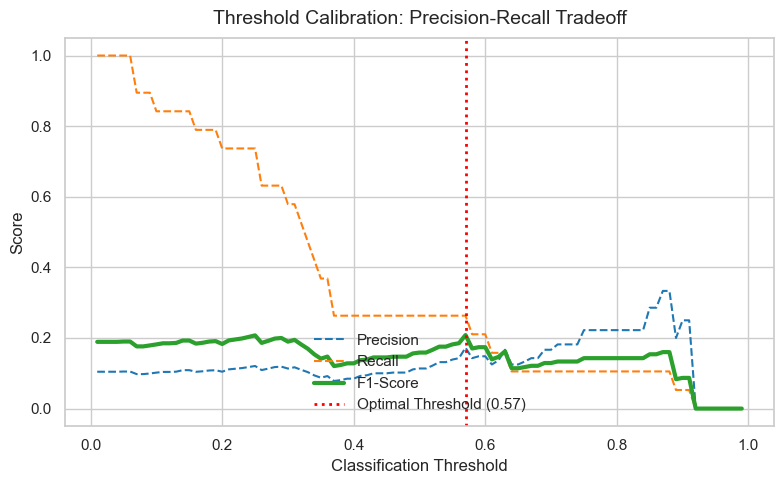

In [71]:
from sklearn.metrics import f1_score, precision_score, recall_score
# 1. THE FIX: Flatten the lists of arrays into single 1D arrays
flat_y_true = np.concatenate(y_true_e_sna)
flat_preds = np.concatenate(preds_e_sna)

# 2. Test thresholds from 0.01 to 0.99
thresholds = np.arange(0.01, 1.0, 0.01)
f1_scores = []
precisions = []
recalls = []

best_f1 = 0
best_thresh = 0
best_recall = 0
best_precision = 0

for t in thresholds:
    # Use the flattened predictions!
    binary_preds = (flat_preds >= t).astype(int)
    
    current_f1 = f1_score(flat_y_true, binary_preds, zero_division=0)
    current_rec = recall_score(flat_y_true, binary_preds, zero_division=0)
    current_prec = precision_score(flat_y_true, binary_preds, zero_division=0)
    
    f1_scores.append(current_f1)
    recalls.append(current_rec)
    precisions.append(current_prec)
    
    # Track the best threshold
    if current_f1 > best_f1:
        best_f1 = current_f1
        best_thresh = t
        best_recall = current_rec
        best_precision = current_prec

print(f"Optimal Threshold:   {best_thresh:.2f}")
print(f"Best F1-Score:       {best_f1:.3f}")
print(f"Resulting Recall:    {best_recall:.3f}")
print(f"Resulting Precision: {best_precision:.3f}")

# ==========================================
# THESIS UPGRADE: Plotting the Threshold Tradeoff
# ==========================================
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

plt.plot(thresholds, precisions, label='Precision', color='#1f77b4', linestyle='--')
plt.plot(thresholds, recalls, label='Recall', color='#ff7f0e', linestyle='--')
plt.plot(thresholds, f1_scores, label='F1-Score', color='#2ca02c', linewidth=3)

# Draw a vertical line at the optimal threshold
plt.axvline(x=best_thresh, color='red', linestyle=':', linewidth=2, 
            label=f'Optimal Threshold ({best_thresh:.2f})')

plt.title('Threshold Calibration: Precision-Recall Tradeoff', fontsize=14, pad=10)
plt.xlabel('Classification Threshold', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.legend(loc='lower center', fontsize=11)

plt.tight_layout()
# Uncomment to save the figure:
plt.savefig("threshold_calibration.png", dpi=300)
plt.show()


K-FOLD RECALL SCORE (Threshold = 0.5700000000000001)
Recall: 0.263



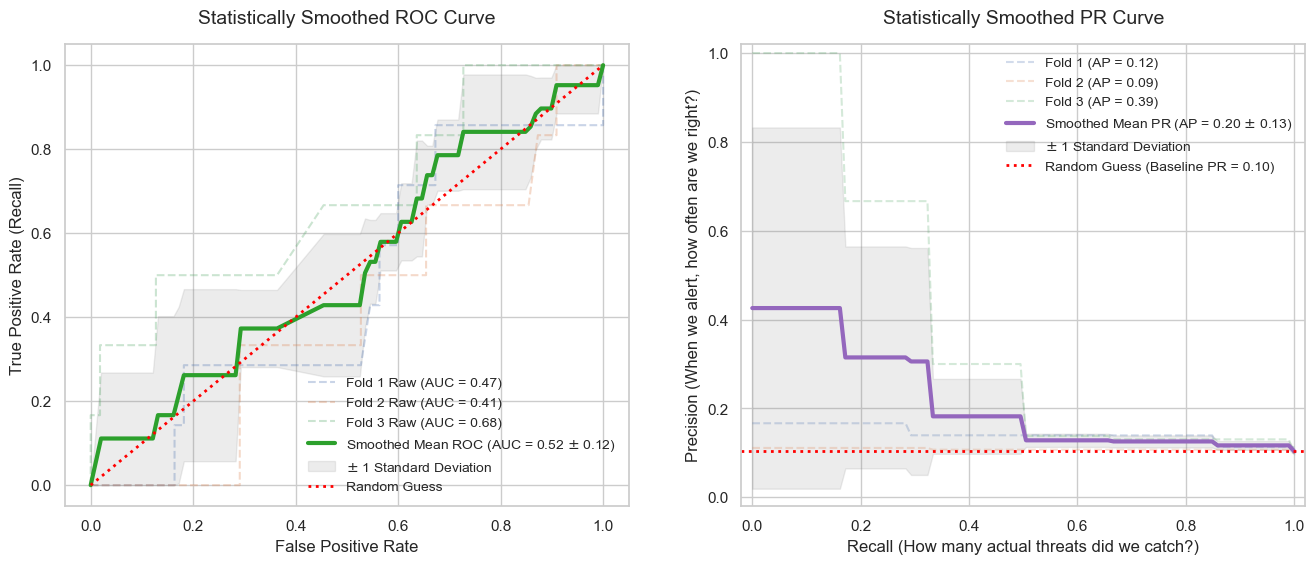

In [72]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score, recall_score

flat_y_true = np.concatenate(y_true_e_sna)
flat_preds = np.concatenate(preds_e_sna)

# 2. Apply your optimized threshold to the flattened probabilities
threshold = best_thresh
binary_preds = (flat_preds >= threshold).astype(int)

# 3. Calculate the honest scores
honest_recall = recall_score(flat_y_true, binary_preds)

print("\n" + "="*40)
print(f"K-FOLD RECALL SCORE (Threshold = {threshold})")
print(f"Recall: {honest_recall:.3f}")
print("="*40 + "\n")

# Grab your K-Fold outputs
y_true_folds = y_true_e_sna
y_prob_folds = preds_e_sna

# Set up the side-by-side canvas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
plt.style.use('seaborn-v0_8-whitegrid')

# ==========================================
# GRAPH 1: SMOOTHED MEAN ROC (Left Side)
# ==========================================
tprs = []
aucs = []
mean_fpr = np.linspace(0, 1, 100) 

for i in range(len(y_true_folds)):
    fpr, tpr, _ = roc_curve(y_true_folds[i], y_prob_folds[i])
    roc_auc = auc(fpr, tpr)
    
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)
    aucs.append(roc_auc)
    
    ax1.plot(fpr, tpr, alpha=0.3, lw=1.5, linestyle='--', label=f'Fold {i+1} Raw (AUC = {roc_auc:.2f})')

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(aucs)

ax1.plot(mean_fpr, mean_tpr, color='#2ca02c', linewidth=3,
        label=r'Smoothed Mean ROC (AUC = %0.2f $\pm$ %0.2f)' % (mean_auc, std_auc))

std_tpr = np.std(tprs, axis=0)
tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
ax1.fill_between(mean_fpr, tprs_lower, tprs_upper, color='grey', alpha=0.15,
                label=r'$\pm$ 1 Standard Deviation')

ax1.plot([0, 1], [0, 1], linestyle=':', lw=2, color='red', label='Random Guess')
ax1.set_title('Statistically Smoothed ROC Curve', fontsize=14, pad=15)
ax1.set_xlabel('False Positive Rate', fontsize=12)
ax1.set_ylabel('True Positive Rate (Recall)', fontsize=12)
ax1.legend(loc="lower right", fontsize=10, framealpha=0.9)


# ==========================================
# GRAPH 2: STATISTICALLY SMOOTHED PR CURVE (Right Side)
# ==========================================
precisions = []
aps = []
mean_recall = np.linspace(0, 1, 100) 

for i in range(len(y_true_folds)):
    precision, recall, _ = precision_recall_curve(y_true_folds[i], y_prob_folds[i])
    fold_ap = average_precision_score(y_true_folds[i], y_prob_folds[i])
    aps.append(fold_ap)
    
    # ---> THE SMOOTHING FIX: Enforce Monotonicity (Max-Precision to the right) <---
    # Since Scikit-Learn outputs recall in descending order, a cumulative max
    # from the front eliminates all the jagged downward drops.
    precision_smoothed = np.maximum.accumulate(precision)
    
    # Interpolate using the smoothed monotonic values
    interp_precision = np.interp(mean_recall, recall[::-1], precision_smoothed[::-1])
    precisions.append(interp_precision)
    
    # Plot the raw folds with the same smoothing so the background matches
    ax2.plot(mean_recall, interp_precision, alpha=0.25, lw=1.5, linestyle='--', 
             label=f'Fold {i+1} (AP = {fold_ap:.2f})')

# Calculate the statistical average (Mean) of the 3 smoothed folds
mean_precision = np.mean(precisions, axis=0)
mean_ap = np.mean(aps)
std_ap = np.std(aps)

# Plot the final beautifully SMOOTHED Mean PR line
ax2.plot(mean_recall, mean_precision, color='#9467bd', linewidth=3,
        label=r'Smoothed Mean PR (AP = %0.2f $\pm$ %0.2f)' % (mean_ap, std_ap))

# Add the grey standard deviation shading
std_precision = np.std(precisions, axis=0)
precisions_upper = np.minimum(mean_precision + std_precision, 1)
precisions_lower = np.maximum(mean_precision - std_precision, 0)
ax2.fill_between(mean_recall, precisions_lower, precisions_upper, color='grey', alpha=0.15,
                label=r'$\pm$ 1 Standard Deviation')

# Format the Baseline
y_true_flat = np.concatenate(y_true_folds)
baseline_pr = sum(y_true_flat) / len(y_true_flat)
ax2.axhline(y=baseline_pr, color='red', linestyle=':', lw=2, 
            label=f'Random Guess (Baseline PR = {baseline_pr:.2f})')

# Format the Graph
ax2.set_title('Statistically Smoothed PR Curve', fontsize=14, pad=15)
ax2.set_xlabel('Recall (How many actual threats did we catch?)', fontsize=12)
ax2.set_ylabel('Precision (When we alert, how often are we right?)', fontsize=12)
ax2.set_xlim([-0.02, 1.02]) # Clean up edges
ax2.set_ylim([-0.02, 1.02])
ax2.legend(loc='upper right', fontsize=10, framealpha=0.9)

# Save and Show
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"final_smoothed_evaluation_dual_{timestamp}.png", dpi=300, bbox_inches='tight')
plt.show()

## Final reports

In [74]:
#import pandas as pd
#from IPython.display import display
#from datetime import datetime
# Assuming generate_threat_report is imported correctly

# FIX 2: Use your scientifically proven threshold!
optimal_threshold = 0.57 
threat_alerts = generate_threat_report(trained_enriched_sna, enriched_data_sna, reverse_mapping, threshold=optimal_threshold)

# FIX 3: Safety check to prevent KeyError on empty DataFrames
if not threat_alerts:
    print(f"✅ No threats detected above the {optimal_threshold*100}% threshold. The yard is safe.")
else:
    # 1. Convert to DataFrame and keep only the columns we need
    df_alerts = pd.DataFrame(threat_alerts)[['source', 'target', 'probability']]

    # 2. Rename columns for the professional output
    df_alerts.columns = ['Source Node', 'Target Node', 'Risk Score']

    # 3. Apply the gradient AND the percentage formatting in one smooth chain!
    styled_table = df_alerts.style.background_gradient(
        subset=['Risk Score'], cmap='Reds', vmin=50.0, vmax=100.0
    ).format(
        {'Risk Score': "{:.1f}%"}
    ).set_caption(f"High-Risk Threat Escalation Report (Threshold: {optimal_threshold})")

    # 4. Save straight to HTML (Optional)
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    # html_filename = f"threat_table_final_{timestamp}.html"
    # styled_table.to_html(html_filename)
    
    # Display the beautiful table directly in your notebook
styled_table

,Source Node,Target Node,Risk Score
0,O'Reilly,Hispanic Inmate,71.3%
1,O'Reilly,Hispanic Inmate,71.3%
2,Unknown_Assailant,Torres,67.9%
3,Smalls,O'Reilly,61.1%
4,Kincaid,Kincaid,61.1%
5,Jackson,O'Reilly,60.7%
6,Jackson,O'Reilly,60.7%
7,Diaz,O'Reilly,60.6%
8,Diaz,O'Reilly,60.6%
9,Runner,Kincaid,59.7%


In [75]:
from neo4j import GraphDatabase
from core.config import graph_base

def enrich_alerts_with_predicates(alerts_list):
    print("🔍 Fetching original semantic predicates from Neo4j...")
    driver = GraphDatabase.driver(graph_base.URL, auth=(graph_base.USER, graph_base.PASS))
    
    with driver.session() as session:
        for alert in alerts_list:
            src = alert['source']
            tgt = alert['target']
            
            # Ask Neo4j what the original LLM-extracted relationship was
            # We explicitly ignore the mathematical SNA edges to get the real action
            query = """
            MATCH (a:Inmate {name: $src})-[r]->(b:Inmate {name: $tgt})
            WHERE type(r) <> 'SNA_TIE_STRENGTH'
            RETURN type(r) AS predicate LIMIT 1
            """
            result = session.run(query, src=src, tgt=tgt).single()
            
            # If Neo4j finds the predicate (e.g., 'ASSAULTS'), save it into the dictionary!
            if result and result['predicate']:
                alert['predicate'] = result['predicate']
            
    driver.close()
    print("✅ Enrichment complete!")
    return alerts_list

# Update your existing alerts list with the real words
threat_alerts = enrich_alerts_with_predicates(threat_alerts)

🔍 Fetching original semantic predicates from Neo4j...
✅ Enrichment complete!


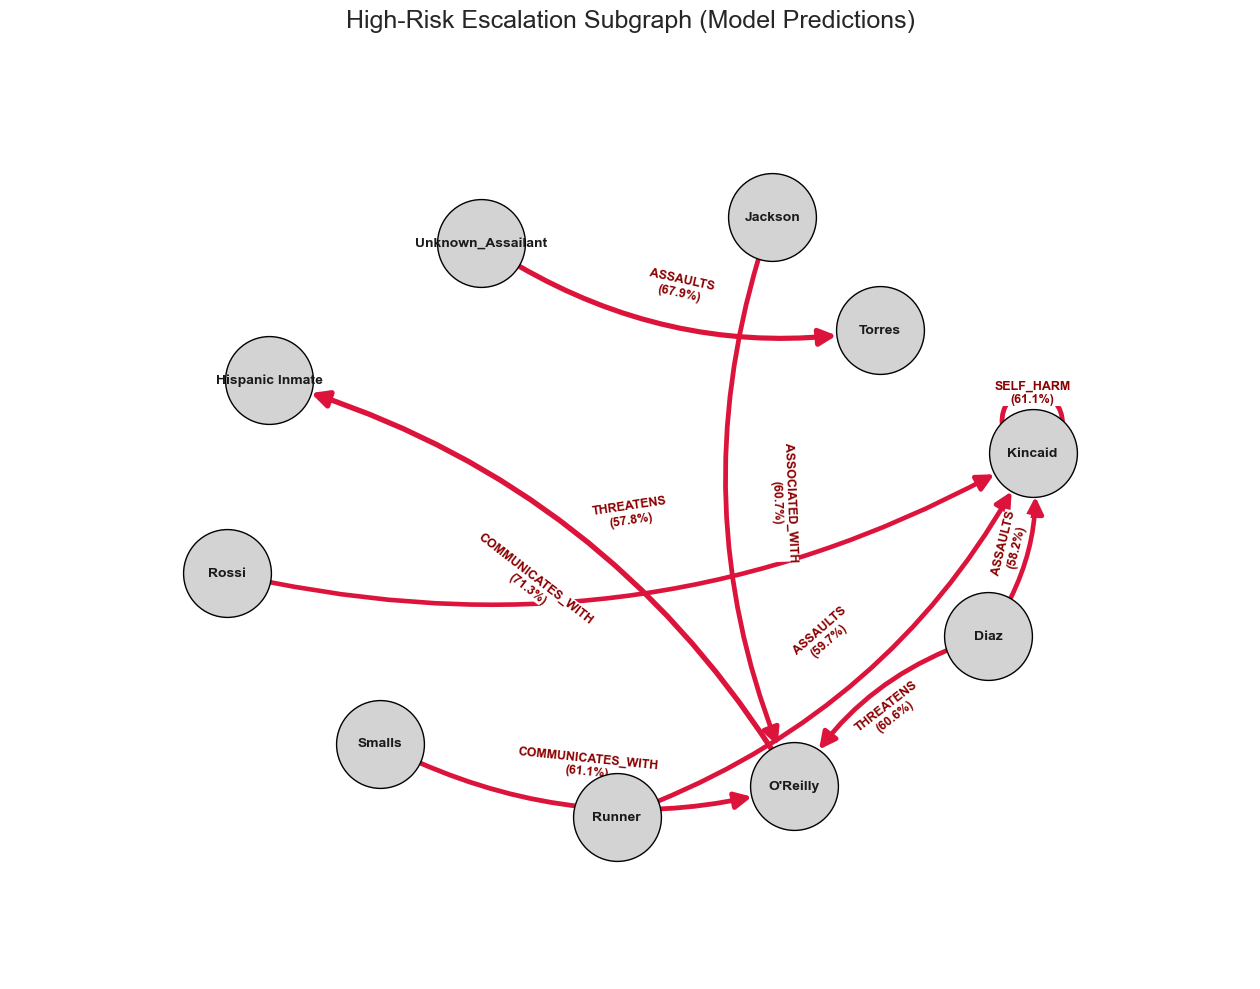

In [78]:
import networkx as nx
import matplotlib.pyplot as plt
from datetime import datetime

# 1. Create a blank, directed graph
G_threat = nx.DiGraph()

# 2. Add edges safely WITH LABELS
for alert in threat_alerts:
    src = alert['source']
    tgt = alert['target']
    
    prob_pct_string = f"{alert['probability']:.1f}%"
    predicate = alert.get('predicate', 'ESCALATES')
    
    arrow_label = f"{predicate}\n({prob_pct_string})"
    
    prob = float(alert['probability'])
    if prob > 1.0: 
        prob = prob / 100.0 
        
    G_threat.add_edge(src, tgt, weight=prob, label=arrow_label)

# 3. Set up a massive canvas
plt.figure(figsize=(16, 12)) # FIX 1: Made the canvas even wider

# FIX 2: The Spring Layout Rescue
# 'k' is the optimal distance between nodes. By setting it high (e.g., 3.5 or 4.0), 
# we force the massive 4000-size nodes to repel each other so they don't overlap.
# 'seed' ensures the graph looks the exact same way every time you run it.
pos = nx.spring_layout(G_threat, k=4.0, iterations=100, seed=15)

NODE_SIZE = 4000

# 4. Draw the Nodes
nx.draw_networkx_nodes(G_threat, pos, node_color='lightgrey', 
                       edgecolors='black', node_size=NODE_SIZE, alpha=1.0)

nx.draw_networkx_labels(G_threat, pos, font_size=10, font_weight='bold')

# 5. Draw the Edges (Arrows)
edge_widths = [1 + (G_threat[u][v]['weight'] * 4) for u, v in G_threat.edges()]

# FIX 3: The Gentle Curve (rad=0.1)
# By adding a 10% curve, bidirectional threats (A->B and B->A) will bow outward,
# allowing you to read both labels clearly without them overlapping!
nx.draw_networkx_edges(G_threat, pos, 
                       arrowstyle='-|>', 
                       arrowsize=25, 
                       edge_color='crimson', 
                       width=edge_widths, 
                       node_size=NODE_SIZE, 
                       connectionstyle="arc3,rad=0.2") 

# 6. Add the Edge Labels
edge_labels = nx.get_edge_attributes(G_threat, 'label')

# NetworkX handles text on curved lines automatically!
nx.draw_networkx_edge_labels(G_threat, pos, edge_labels=edge_labels, 
                             font_color='darkred', font_size=9, font_weight='bold',
                             bbox=dict(facecolor='white', edgecolor='none', alpha=1.0, pad=0.3))

# 7. Formatting
plt.title("High-Risk Escalation Subgraph (Model Predictions)", fontsize=18, pad=20)
plt.margins(0.2) # FIX 4: Give the graph a 20% buffer so edge nodes don't get cut off
plt.axis('off')

# Save and show
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"threat_subgraph_final_{timestamp}.png", dpi=300, bbox_inches='tight')

plt.show()